In [1]:
# Nombre: Cristina Maureira     Rut: 22.356.447-k
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Esto lo usé para saber los nombres de las columnas
data = np.load('catalogo_100000_estrellas.npz')
data.files

['nombre', 'L_Lsol', 'd_pc', 'T_K']

In [3]:
# configuración para las figuras
plt.rcParams.update({
    "figure.figsize": (12, 7),
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.constrained_layout.use": True,
})
# configuración para los DataFrame
pd.options.display.float_format = '{:.3e}'.format

In [4]:
class CatalogoEstelar:
    """
    Analizar y procesa un catálogo estelar a partir de un archivo .npz
    
    Parameters
    ----------
    ruta_npz : str, opcional
        Ruta del archivo .npz que contiene los datos estelares. Por defecto es None
    umbral : float, opcional
            Umbral de detección de flujo en Wm⁻². Por defecto es 1e-14
    bins : int, opcional
            Número de intervalos utilizados en los histogramas. Por defecto es 30.

    Attributes
    ----------
    ruta_npz : str
        Ruta del archivo
    datos : pd.DataFrame
        DataFrame del catálogo
    limpiar_datos : pd.DataFrame
        DataFrame limpio de valores negativos y nan

    Methods
    -------
    cargar_npz()
        Carga el archivo npz desde su ruta y devuelve un DataFrame
    limpiar_datos()
        Limpia los datos del DataFrame de valores negativos y nan
    calcular_flujo()
        Calcula el flujo en Wm⁻² y crea una nueva columna en el DataFrame
    calcular_radio()
        Calcula el radio en R☉ y crea una nueva columna en el DataFrame
    calcular_magnitud()
        Calcula la magnitud bolométrica y crea una nueva columna en el DataFrame
    calcular_lamda_max()
        Calcula el lambda de máxima emision y crea una nueva columna en el DataFrame
    clasificar_deteccion(umbral)
        Determina qué estrellas fueron detectadas a partir de sus flujos bolométricos
    estadisticas()
        Entrega media, mediana, desviación estándar, perentil 25, 50 y 75, mínimos y máximos, además de identificar
        las estrellas de los minimos y máximos de luminosidad bol., temperatura efectiva y radio estelar
    resumen_por_temperatura(umbral)
        Clasifica las estrellas en frías, intermedias o calientes
    graficar_hr()
        Grafica diagrama de Hertzsprung-Russell de luminosidad bolométrico en función a la temperatura efectiva
    graficar_histogramas(bins)
        Grafica histogramas de luminosidad, distancia, temperatura, radio y magnitud
    graficar_temperatura_flujo(umbral)
        Grafica una figura de dos paneles, el izquierdo un histograma de temperaturas efectivas, y el derecho un
        scatter del flujo bolométrico en función a la distancia
    graficar_grupos(umbral)
        Construye un figura de dos graficos de barras, el número de estrellas detectadas en los grupos de temperaturas y
        la fracción que hay de estas en cada grupo
    guardar_resultados()
        Exporta el catálogo a csv o npz.
    """
    def __init__(self, ruta_npz=None):
        """
        Inicializa la clase, carga los datos y ejecuta la limpieza automática.

        Parameters
        ----------
        ruta_archivo : str, opcional
            Ruta del archivo npz. Por defecto es None
        """
        self.ruta_npz = ruta_npz
        if ruta_npz is not None:
            self.datos = self.cargar_npz()
            self.limpiar_datos() # Limpia los datos automáticamente al inicializar
    def cargar_npz(self):
        """
        Lee los datos desde un archivo npz y los almacena en un DataFrame de pandas.

        Returns
        -------
        pd.DataFrame
            Un DataFrame con las columnas de nombres, luminosidades, 
            distancias y temperaturas efectivas.
        """
        # Se carga el archivo npz
        with np.load(self.ruta_npz, allow_pickle=True) as data:
            nombres = data['nombre'].flatten()  # como los calculos salian con el mismo resultado le aplique flatten()
            luminosidades = data['L_Lsol'].flatten()
            distancias = data['d_pc'].flatten()
            temperaturas = data['T_K'].flatten()
        # y entonces se crea el dataframe con los datos del npz
        df = pd.DataFrame({ 'nombre': nombres,
            'luminosidad [L☉]': luminosidades,
            'distancia [pc]': distancias,
            'temperatura [K]': temperaturas})
        return df
    def limpiar_datos(self):
        """
        Identifica y trata los valores faltantes nan e inválidos (negativos) en el catálogo.

        Estrategia utilizada
        --------------------
        Se eliminaron todas las filas en las que hubo un valor nan o negativo.
        """
        cant_datos_in = len(self.datos)
        print(f"Número de datos inicial: {cant_datos_in}")
        columnas = ['luminosidad [L☉]', 'distancia [pc]', 'temperatura [K]'] # Se seleccionan solo las columnas con valores físicos
        condicion_negativos = (self.datos[columnas] < 0).any(axis=1) # Máscara booleana de valores negativos en el eje horizontal
        print(f"Cantidad de números negativos: {condicion_negativos.sum()}")
        print(f"Cantidad de nan: {self.datos.isna().any(axis=1).sum()}")
        self.datos = self.datos[~condicion_negativos].dropna().reset_index(drop=True) # Se extraen los negativos y nan y se restauran los índices
        print(f"Número de datos útiles: {len(self.datos)}")
        return self.datos
    def calcular_flujo(self):
        """
        Calcula y regresa el DataFrame con el flujo bolométrico obtenido de cada estrella en Wm⁻²
        """
        L = self.datos['luminosidad [L☉]'] * 3.828e26 # de Lsol a vatios
        d = self.datos['distancia [pc]'] * 3.086e16 # de pc a metros
        f_bol = L / (4 * np.pi * (d ** 2))
        self.datos['flujo bolométrico [Wm⁻²]'] = f_bol
        return self.datos
    def calcular_radio(self):
        """
        Calcula y regresa el DataFrame con el radio estelar obtenido de cada estrella en R☉
        """
        L = self.datos['luminosidad [L☉]']
        T = self.datos['temperatura [K]']
        radio = np.sqrt(L) * ((5778 / T) ** 2) # El 5778 es la temperatura solar
        self.datos['radio estelar [R☉]'] = radio
        return self.datos
    def calcular_magnitud(self):
        """
        Calcula y regresa el DataFrame con la magnitud bolométrica de cada estrella
        """
        # En cada cálculo se usa el mismo procedimiento de definir las variables según el DataFrame
        L = self.datos['luminosidad [L☉]']
        m_bol = 4.74 - 2.5 * np.log10(L)
        self.datos['magnitud bolométrica'] = m_bol
        return self.datos
    def calcular_lambda_max(self):
        """
        Calcula y regresa el DataFrame con el lambda de máxima emisión de cada estrella en nm
        """
        b = 2.8978e-3 * 1e9 # de metros a nanometros
        T = self.datos['temperatura [K]']
        lambda_max = b / T
        self.datos['lambda de máxima emisión [nm]'] = lambda_max
        return self.datos
    def clasificar_deteccion(self, umbral=1e-14):
        """
        Clasifica las detecciónes (desconocida, detectada, no detectada) según el flujo si es que
        supera un umbral o es nan
        
        Parameters
        ----------
        umbral : float, opcional
            Umbral de detección de flujo en Wm⁻². Por defecto es 1e-14.
        """
        flujo = self.datos['flujo bolométrico [Wm⁻²]']
        condiciones = [ # Se definen las 3 condiciones
            flujo.isna(), # Si el dato en nan
            flujo >= umbral, # Si el dato está encima del umbral
            flujo < umbral] # Si el dato está debajo del umbral
        opciones = ['desconocida', 'detectada', 'no detectada'] # Y en el mismo orden que las condiciones se definen sus calificaciones(valores)
        # desconocida = nan, detectada = encima del umbral, no detectada = debajo del umbral
        self.datos['clasificación'] = np.select(condiciones, opciones, default='desconocida')
        return self.datos           # np.select permite aplicar multiples condiciones con valores definidos a cada una
    def estadisticas(self):
        """
        Entrega las estadísticas de media aritmética, mediana, desviación estándar,
        percentiles (25, 50, 75) y valores mínimos y máximos sobre cada variable (columna)
        """
        estadisticas = self.datos.describe().T # entrega todas las mediciones (la mediana es lo mismo que el percentil 50)
        propiedades_extremas = ['luminosidad [L☉]', 'temperatura [K]', 'radio estelar [R☉]']
        print('----------Estrellas Extremas Detectadas----------')
        for col in propiedades_extremas:
            if col in self.datos.columns:
                # índice del valor mínimo y máximo
                idx_min = self.datos[col].idxmin()
                idx_max = self.datos[col].idxmax()
                # los nombres de las estrellas correspondientes y sus valores
                nombre_min = self.datos.loc[idx_min, 'nombre']
                valor_min = self.datos.loc[idx_min, col]
                nombre_max = self.datos.loc[idx_max, 'nombre']
                valor_max = self.datos.loc[idx_max, col]
                print(f"{col}")
                print(f"Mínimo: Estrella '{nombre_min}' con {valor_min:.3e}")
                print(f"Máximo: Estrella '{nombre_max}' con {valor_max:.3e}")
        return estadisticas
    def resumen_por_temperatura(self, umbral=1e-14):
        """
        Clasifica las estrellas según temperaturas y genera un resumen
        de sus propiedades físicas y su tasa de detección.

        Parameters
        ----------
        umbral : float, opcional
            Umbral de detección de flujo en Wm⁻². Por defecto es 1e-14.
        """
        bins = [-np.inf, 5000, 7500, np.inf] # se definen los límites
        labels = ['Fría', 'Intermedia', 'Caliente'] # las clasificaciones
        self.datos['grupo temperatura'] = pd.cut(
            self.datos['temperatura [K]'], 
            bins=bins, 
            labels=labels, 
            right=False)
        # se usó la cantidad de detectadas (unos) para calcular la fracción de detectadas con el promedio
        self.datos['aux_f_det'] = self.datos['clasificación'].map({
            'detectada': 1.0,
            'no detectada': 0.0,
            'desconocida': np.nan})
        # Agrupar y aplicar las agregaciones con agg()
        resumen = self.datos.groupby('grupo temperatura', observed=False).agg(
            total_validas=('temperatura [K]', 'count'),
            temp_media=('temperatura [K]', 'mean'),
            lumi_media=('luminosidad [L☉]', 'mean'),
            flujo_mediano=('flujo bolométrico [Wm⁻²]', 'median'),
            f_det=('aux_f_det', 'mean'))
        # Se saca la columna auxiliar
        self.datos = self.datos.drop(columns=['aux_f_det'])
        # Y, finalmente, se nombran las columnas
        resumen.columns = [
            'total Estrellas (T válida)',
            'temperatura Media [K]',
            'luminosidad Media [L☉]',
            'flujo Mediano [Wm⁻²]',
            'fracción Detectadas']
        return resumen
    def graficar_hr(self):
        """
        Crea un Diagrama de Hertzsprung-Russell graficando la luminosidad en función de la temperatura efectiva,
        además, configura el eje de luminosidad en escala logarítmica e invierte el eje de temperatura.
        """
        plt.figure()
        plt.scatter(
            self.datos['temperatura [K]'], 
            self.datos['luminosidad [L☉]'], 
            s=1,
            alpha=0.5, 
            color='royalblue')
        plt.yscale('log') # la luminosidad a escala logrítmica
        plt.gca().invert_xaxis() # se invierten las temperaturas
        plt.xlabel(r'Temperatura [$K$]')
        plt.ylabel(r'Luminosidad [$L\odot$]')
        plt.title('Diagrama de Hertzsprung-Russell')
        plt.show()
    def graficar_histogramas(self, bins=30):
        """
        Construye una cuadrícula de histogramas para representar las distribuciones
        de los principales parámetros físicos de las estrellas del catálogo.

        Parameters
        ----------
        bins : int, opcional
            Número de intervalos utilizados en los histogramas. Por defecto es 30.
        """
        fig, ax = plt.subplots(2, 3, sharey=False)
        axes = ax.flatten() # Se aplana la matriz a un arreglo 1D para poder iterarlo
        config_graficas = [ # Aquí se definen las columnas que se graficarán, sus etiquetas y si seran usados en log10
            ('luminosidad [L☉]', r'Luminosidad [$L_{\odot}$]', True),
            ('distancia [pc]', 'Distancia [pc]', False),
            ('temperatura [K]', 'Temperatura Efectiva [K]', False),
            ('radio estelar [R☉]', r'Radio Estelar [$R_{\odot}$]', False),
            ('magnitud bolométrica', 'Magnitud Bolométrica', False)]
        # iteración y construcción de cada histograma
        for i, (columna, etiqueta, log_x) in enumerate(config_graficas):
            sub_ax = axes[i]
            if log_x:
                # si la variable requiere escala logarítmica en el eje X (como la Luminosidad)
                # el logspace crea un conjunto de números distribuidos de forma equitativa en una escala logarítmica para
                # que el histograma no se vea deforme
                intervalos_log = np.logspace(np.log10(self.datos[columna].min()), np.log10(self.datos[columna].max()), bins)
                sub_ax.hist(self.datos[columna], bins=intervalos_log, edgecolor='white')
                sub_ax.set_xscale('log')
            else:
                # Histograma estándar lineal
                sub_ax.hist(self.datos[columna], bins=bins, edgecolor='white')
            # Formatear el subplot respetando el estilo del entorno
            sub_ax.set_title(f'Distribución de {columna}', fontsize=10)
            sub_ax.set_xlabel(etiqueta)
            sub_ax.set_ylabel('Frecuencia')
        # apagar el sexto subplot (esquina inferior derecha) ya que solo hay 5 variables
        axes[5].axis('off')
        # Ajustar el diseño para que las etiquetas no se encimen entre subplots
        plt.show()
    def graficar_temperatura_flujo(self, umbral=1e-14):
        """
        Construye una figura de dos paneles para analizar las temperaturas
        y la relación entre distancia y flujo de las estrellas del catálogo.
        Panel izquierdo: Histograma de temperaturas efectivas.
        Panel derecho: Gráfico de dispersión de flujo en función de la distancia,
                       coloreado por temperatura y con una línea de umbral.

        Parameters
        ----------
        umbral : float, opcional
            Umbral de detección de flujo en Wm⁻². Por defecto es 1e-14.
        """
        fig, ax = plt.subplots(1, 2, sharey=False)
        ax[0].hist(self.datos['temperatura [K]'], edgecolor='white') # histograma de la temperatura
        ax[0].set_title('Distribución de Temperaturas Efectivas')
        ax[0].set_xlabel('Temperatura Efectiva [K]')
        ax[0].set_ylabel('Número de Estrellas')
        ax[0].set_ylim(bottom=5500) # achiqué el eje y para que se note más la diferencia del n° de estrellas
        scatter = ax[1].scatter( # scatter de distancia, flujo y temperatura
            self.datos['distancia [pc]'], # eje x
            self.datos['flujo bolométrico [Wm⁻²]'], # eje y 
            c=self.datos['temperatura [K]'], 
            cmap='plasma', # color del cmap
            s=2) # puntos pequeños por la alta densidad de estrellas)
        ax[1].set_yscale('log') # escala logarítmica del flujo
        ax[1].axhline(umbral, color='red', linestyle='--', linewidth=1.5, label=f'Umbral ({umbral} Wm$^{{-2}}$)') # linea del umbral
        cbar = fig.colorbar(scatter, ax=ax[1]) # colorbar
        cbar.set_label('Temperatura Efectiva [K]') # etiqueta del cbar
        ax[1].set_title('Flujo Bolométrico vs. Distancia') # título
        ax[1].set_xlabel('Distancia [pc]') # etiqueta eje x
        ax[1].set_ylabel(r'Flujo Bolométrico (Wm$^{-2}$)') # etiqueta eje y
        ax[1].legend(loc='upper right') # leyenda en la parte superior derecha
    def graficar_grupos(self, umbral=1e-14):
        """
        Construye una figura con dos gráficos de barras basados en los resultados
        de resumen_por_temperatura().
        Panel izquierdo: Número total de estrellas en cada grupo de temperatura.
        Panel derecho: Fracción de estrellas detectadas (f_det) en cada grupo.

        Parameters
        ----------
        umbral : float, opcional
            Umbral de detección de flujo en Wm⁻². Por defecto es 1e-14.
        """
        grupos = self.resumen_por_temperatura().index.astype(str) # se ponen los grupos en tipo string
        fig, ax = plt.subplots(1, 2, sharey=False) # se crea una figura de dos paneles
        ax[0].bar(grupos, self.resumen_por_temperatura()['total Estrellas (T válida)'], edgecolor='white') # histograma de n°estrellas por grupo
        ax[0].set_title('Distribución de grupos de temperatura', fontsize=10)
        ax[0].set_xlabel('Grupos de temperaturas')
        ax[0].set_ylabel('Número de estrellas')
        ax[1].bar(grupos, self.resumen_por_temperatura()['fracción Detectadas'], edgecolor='white')  # histograma de fracción detectadas por grupo
        ax[1].set_title('Distribución de fracción de estrellas detectadas', fontsize=10)
        ax[1].set_xlabel('Grupos de temperaturas')
        ax[1].set_ylabel('fracción de estrellas detectadas')
    def guardar_resultados(self, nombre_archivo="catalogo_procesado", formato="csv"):
        """
        Exporta el catálogo estelar totalmente procesado a un archivo externo,
        incluyendo todas las propiedades físicas y clasificaciones calculadas.

        Parameters
        ----------
        nombre_archivo : str, opcional
            Nombre base del archivo de salida (sin extensión). 
            Por defecto es "catalogo_procesado".
        formato : str, opcional
            Formato de exportación: 'csv' o 'npz'. Por defecto es 'csv'.
        """
        print('Guardando archivo...')
        if formato.lower() == "csv":
            ruta_salida = f"{nombre_archivo}.csv"
            # index=False evita guardar la columna numérica de índices de Pandas
            self.datos.to_csv(ruta_salida, index=False)
            print(f"Archivo CSV exportado exitosamente en: '{ruta_salida}'")
        elif formato.lower() == "npz":
            ruta_salida = f"{nombre_archivo}.npz"
            # se convierte cada columna del DataFrame de vuelta a arreglos independientes de NumPy
            np.savez_compressed( # solo se salvan las columnas que ya existian o se calcularon
                ruta_salida,
                nombres=self.datos['nombre'].to_numpy(),
                luminosidades=self.datos['luminosidad [L☉]'].to_numpy(),
                distancias=self.datos['distancia [pc]'].to_numpy(),
                temperaturas=self.datos['temperatura [K]'].to_numpy(),
                flujo_bolometrico=self.datos['flujo bolométrico [Wm⁻²]'].to_numpy() if 'flujo bolométrico [Wm⁻²]' in self.datos.columns else None,
                radio_solar=self.datos['radio estelar [R☉]'].to_numpy() if 'radio estelar [R☉]' in self.datos.columns else None,
                magnitud_bolometricica=self.datos['magnitud bolométrica'].to_numpy() if 'magnitud bolométrica' in self.datos.columns else None,
                lambda_max_nm=self.datos['lambda de máxima emisión [nm]'].to_numpy() if 'lambda de máxima emisión [nm]' in self.datos.columns else None,
                clasificacion=self.datos['clasificación'].to_numpy() if 'clasificación' in self.datos.columns else None)
            print(f"Archivo NPZ comprimido exportado exitosamente en: '{ruta_salida}'")
        else:
            print(f"Error: Formato '{formato}' no reconocido. Utiliza 'csv' o 'npz'")
    @classmethod
    def desde_dataframe(cls, df_externo: pd.DataFrame):
        """
        Constructor alternativo que crea una instancia de CatalogoEstelar 
        directamente a partir de un objeto pandas.DataFrame existente.

        Parameters
        ----------
        df_externo : pd.DataFrame
            DataFrame con las columnas estelares.

        Returns
        -------
        CatalogoEstelar
            Una nueva instancia de la clase con los datos cargados y limpios.
        """
        # instancia "vacía" de la clase (pasa None al __init__)
        instancia = cls(ruta_npz=None)
        # cambiar el nombre a las columnas para asegurar que todo el resto de métodos de la clase sigan funcionando sin cambios
        columnas_mapeo = {
            'L_Lsol': 'luminosidad [L☉]',
            'd_pc': 'distancia [pc]',
            'T_K': 'temperatura [K]'}
        # se hace una copia para no alterar el DataFrame original del usuario
        df_copia = df_externo.rename(columns=columnas_mapeo).copy()
        # asignación del DataFrame al atributo interno .datos de la nueva instancia
        instancia.datos = df_copia
        # limpieza de datos
        instancia.limpiar_datos()
        return instancia

In [5]:
mi_catalogo = CatalogoEstelar('catalogo_100000_estrellas.npz')

Número de datos inicial: 100000
Cantidad de números negativos: 14315
Cantidad de nan: 27013
Número de datos útiles: 61403


In [6]:
mi_catalogo.calcular_flujo()

,nombre,luminosidad [L☉],distancia [pc],temperatura [K],flujo bolométrico [Wm⁻²]
0,Estrella_0000,7.742e+01,4.725e+02,5.826e+03,1.109e-11
1,Estrella_0001,4.394e+01,4.764e+02,5.743e+03,6.193e-12
2,Estrella_0003,6.977e+01,1.629e+02,7.043e+03,8.411e-11
3,Estrella_0004,9.508e+00,3.827e+02,8.320e+03,2.077e-12
4,Estrella_0007,7.863e+01,4.334e+02,8.013e+03,1.339e-11
...,...,...,...,...,...
61398,Estrella_99991,8.138e+01,2.691e+02,6.849e+03,3.593e-11
61399,Estrella_99994,6.938e+01,3.359e+02,8.303e+03,1.967e-11
61400,Estrella_99997,5.604e+01,1.394e+02,6.477e+03,9.227e-11
61401,Estrella_99998,1.219e+01,9.929e+01,3.744e+03,3.956e-11


In [7]:
mi_catalogo.calcular_radio()

,nombre,luminosidad [L☉],distancia [pc],temperatura [K],flujo bolométrico [Wm⁻²],radio estelar [R☉]
0,Estrella_0000,7.742e+01,4.725e+02,5.826e+03,1.109e-11,8.655e+00
1,Estrella_0001,4.394e+01,4.764e+02,5.743e+03,6.193e-12,6.711e+00
2,Estrella_0003,6.977e+01,1.629e+02,7.043e+03,8.411e-11,5.621e+00
3,Estrella_0004,9.508e+00,3.827e+02,8.320e+03,2.077e-12,1.487e+00
4,Estrella_0007,7.863e+01,4.334e+02,8.013e+03,1.339e-11,4.610e+00
...,...,...,...,...,...,...
61398,Estrella_99991,8.138e+01,2.691e+02,6.849e+03,3.593e-11,6.420e+00
61399,Estrella_99994,6.938e+01,3.359e+02,8.303e+03,1.967e-11,4.033e+00
61400,Estrella_99997,5.604e+01,1.394e+02,6.477e+03,9.227e-11,5.957e+00
61401,Estrella_99998,1.219e+01,9.929e+01,3.744e+03,3.956e-11,8.316e+00


In [8]:
mi_catalogo.calcular_magnitud()

,nombre,luminosidad [L☉],distancia [pc],temperatura [K],flujo bolométrico [Wm⁻²],radio estelar [R☉],magnitud bolométrica
0,Estrella_0000,7.742e+01,4.725e+02,5.826e+03,1.109e-11,8.655e+00,1.789e-02
1,Estrella_0001,4.394e+01,4.764e+02,5.743e+03,6.193e-12,6.711e+00,6.328e-01
2,Estrella_0003,6.977e+01,1.629e+02,7.043e+03,8.411e-11,5.621e+00,1.309e-01
3,Estrella_0004,9.508e+00,3.827e+02,8.320e+03,2.077e-12,1.487e+00,2.295e+00
4,Estrella_0007,7.863e+01,4.334e+02,8.013e+03,1.339e-11,4.610e+00,1.059e-03
...,...,...,...,...,...,...,...
61398,Estrella_99991,8.138e+01,2.691e+02,6.849e+03,3.593e-11,6.420e+00,-3.623e-02
61399,Estrella_99994,6.938e+01,3.359e+02,8.303e+03,1.967e-11,4.033e+00,1.369e-01
61400,Estrella_99997,5.604e+01,1.394e+02,6.477e+03,9.227e-11,5.957e+00,3.687e-01
61401,Estrella_99998,1.219e+01,9.929e+01,3.744e+03,3.956e-11,8.316e+00,2.025e+00


In [9]:
mi_catalogo.calcular_lambda_max()

,nombre,luminosidad [L☉],distancia [pc],temperatura [K],flujo bolométrico [Wm⁻²],radio estelar [R☉],magnitud bolométrica,lambda de máxima emisión [nm]
0,Estrella_0000,7.742e+01,4.725e+02,5.826e+03,1.109e-11,8.655e+00,1.789e-02,4.974e+02
1,Estrella_0001,4.394e+01,4.764e+02,5.743e+03,6.193e-12,6.711e+00,6.328e-01,5.046e+02
2,Estrella_0003,6.977e+01,1.629e+02,7.043e+03,8.411e-11,5.621e+00,1.309e-01,4.114e+02
3,Estrella_0004,9.508e+00,3.827e+02,8.320e+03,2.077e-12,1.487e+00,2.295e+00,3.483e+02
4,Estrella_0007,7.863e+01,4.334e+02,8.013e+03,1.339e-11,4.610e+00,1.059e-03,3.616e+02
...,...,...,...,...,...,...,...,...
61398,Estrella_99991,8.138e+01,2.691e+02,6.849e+03,3.593e-11,6.420e+00,-3.623e-02,4.231e+02
61399,Estrella_99994,6.938e+01,3.359e+02,8.303e+03,1.967e-11,4.033e+00,1.369e-01,3.490e+02
61400,Estrella_99997,5.604e+01,1.394e+02,6.477e+03,9.227e-11,5.957e+00,3.687e-01,4.474e+02
61401,Estrella_99998,1.219e+01,9.929e+01,3.744e+03,3.956e-11,8.316e+00,2.025e+00,7.740e+02


In [21]:
mi_catalogo.clasificar_deteccion(1e-12)

,nombre,luminosidad [L☉],distancia [pc],temperatura [K],flujo bolométrico [Wm⁻²],radio estelar [R☉],magnitud bolométrica,lambda de máxima emisión [nm],clasificación,grupo temperatura
0,Estrella_0000,7.742e+01,4.725e+02,5.826e+03,1.109e-11,8.655e+00,1.789e-02,4.974e+02,detectada,Intermedia
1,Estrella_0001,4.394e+01,4.764e+02,5.743e+03,6.193e-12,6.711e+00,6.328e-01,5.046e+02,detectada,Intermedia
2,Estrella_0003,6.977e+01,1.629e+02,7.043e+03,8.411e-11,5.621e+00,1.309e-01,4.114e+02,detectada,Intermedia
3,Estrella_0004,9.508e+00,3.827e+02,8.320e+03,2.077e-12,1.487e+00,2.295e+00,3.483e+02,detectada,Caliente
4,Estrella_0007,7.863e+01,4.334e+02,8.013e+03,1.339e-11,4.610e+00,1.059e-03,3.616e+02,detectada,Caliente
...,...,...,...,...,...,...,...,...,...,...
61398,Estrella_99991,8.138e+01,2.691e+02,6.849e+03,3.593e-11,6.420e+00,-3.623e-02,4.231e+02,detectada,Intermedia
61399,Estrella_99994,6.938e+01,3.359e+02,8.303e+03,1.967e-11,4.033e+00,1.369e-01,3.490e+02,detectada,Caliente
61400,Estrella_99997,5.604e+01,1.394e+02,6.477e+03,9.227e-11,5.957e+00,3.687e-01,4.474e+02,detectada,Intermedia
61401,Estrella_99998,1.219e+01,9.929e+01,3.744e+03,3.956e-11,8.316e+00,2.025e+00,7.740e+02,detectada,Fría


In [22]:
mi_catalogo.estadisticas()

----------Estrellas Extremas Detectadas----------
luminosidad [L☉]
Mínimo: Estrella 'Estrella_10217' con 1.013e-01
Máximo: Estrella 'Estrella_45903' con 1.000e+02
temperatura [K]
Mínimo: Estrella 'Estrella_5058' con 3.000e+03
Máximo: Estrella 'Estrella_70445' con 1.000e+04
radio estelar [R☉]
Mínimo: Estrella 'Estrella_62716' con 1.131e-01
Máximo: Estrella 'Estrella_2395' con 3.687e+01


,count,mean,std,min,25%,50%,75%,max
luminosidad [L☉],6.140e+04,5.007e+01,2.884e+01,1.013e-01,2.509e+01,5.023e+01,7.505e+01,1.000e+02
distancia [pc],6.140e+04,2.746e+02,1.299e+02,5.001e+01,1.618e+02,2.739e+02,3.868e+02,5.000e+02
temperatura [K],6.140e+04,6.501e+03,2.016e+03,3.000e+03,4.750e+03,6.503e+03,8.252e+03,1.000e+04
flujo bolométrico [Wm⁻²],6.140e+04,6.356e-11,1.254e-10,1.470e-14,8.653e-12,1.905e-11,5.480e-11,1.268e-09
radio estelar [R☉],6.140e+04,7.417e+00,6.361e+00,1.131e-01,3.133e+00,5.077e+00,9.597e+00,3.687e+01
magnitud bolométrica,6.140e+04,8.192e-01,1.064e+00,-2.600e-01,5.163e-02,4.875e-01,1.241e+00,7.226e+00
lambda de máxima emisión [nm],6.140e+04,4.981e+02,1.771e+02,2.898e+02,3.512e+02,4.456e+02,6.100e+02,9.659e+02


In [23]:
mi_catalogo.resumen_por_temperatura(1e-12)

,total Estrellas (T válida),temperatura Media [K],luminosidad Media [L☉],flujo Mediano [Wm⁻²],fracción Detectadas
grupo temperatura,,,,,
Fría,17463,3.998e+03,4.998e+01,1.910e-11,9.714e-01
Intermedia,21971,6.251e+03,5.026e+01,1.918e-11,9.742e-01
Caliente,21969,8.742e+03,4.994e+01,1.884e-11,9.709e-01


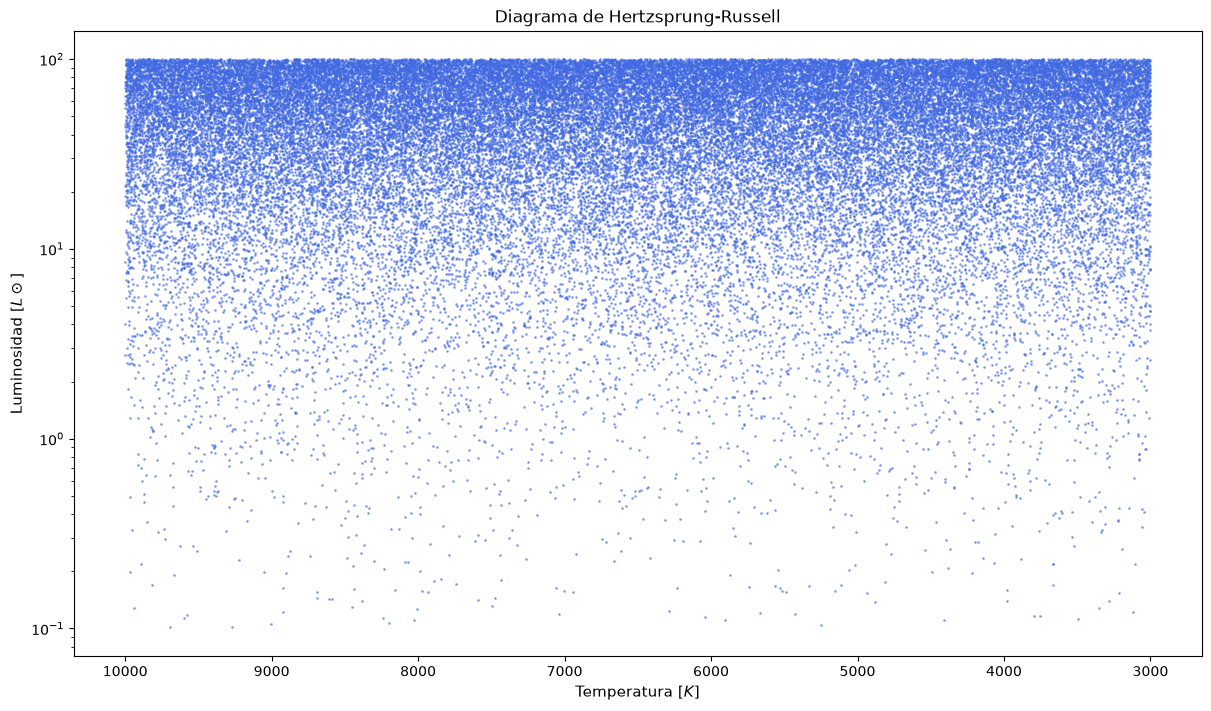

In [24]:
mi_catalogo.graficar_hr()

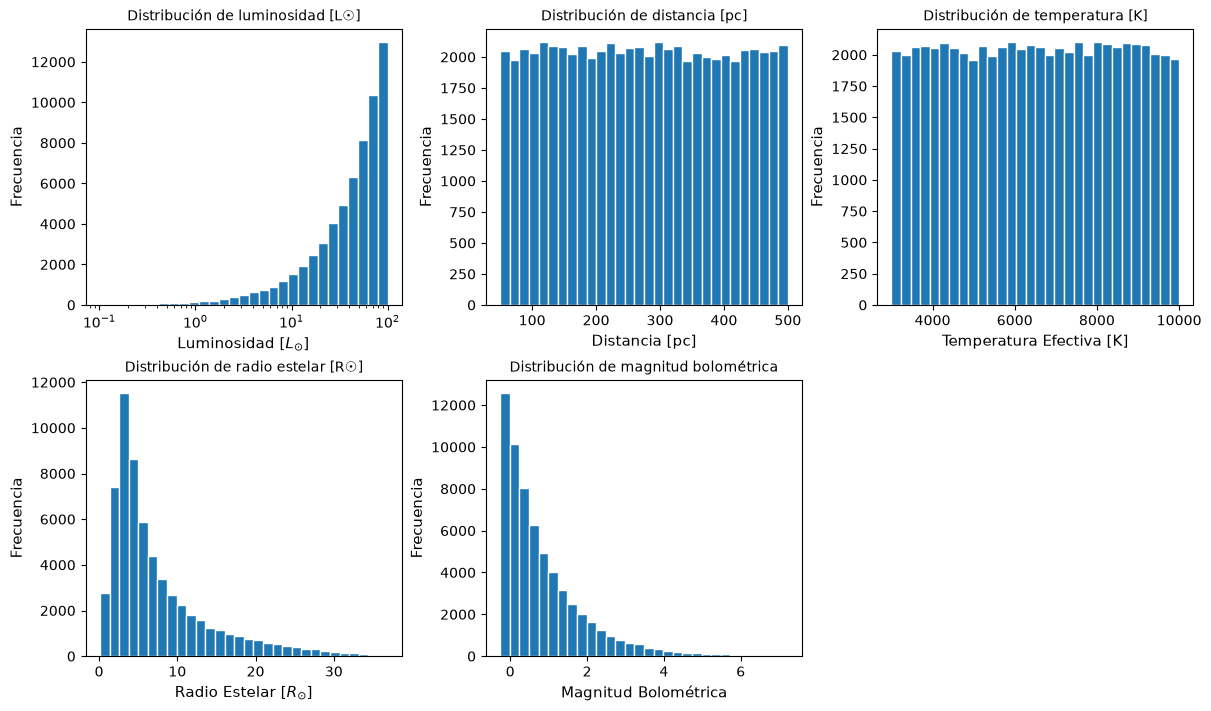

In [25]:
mi_catalogo.graficar_histogramas()

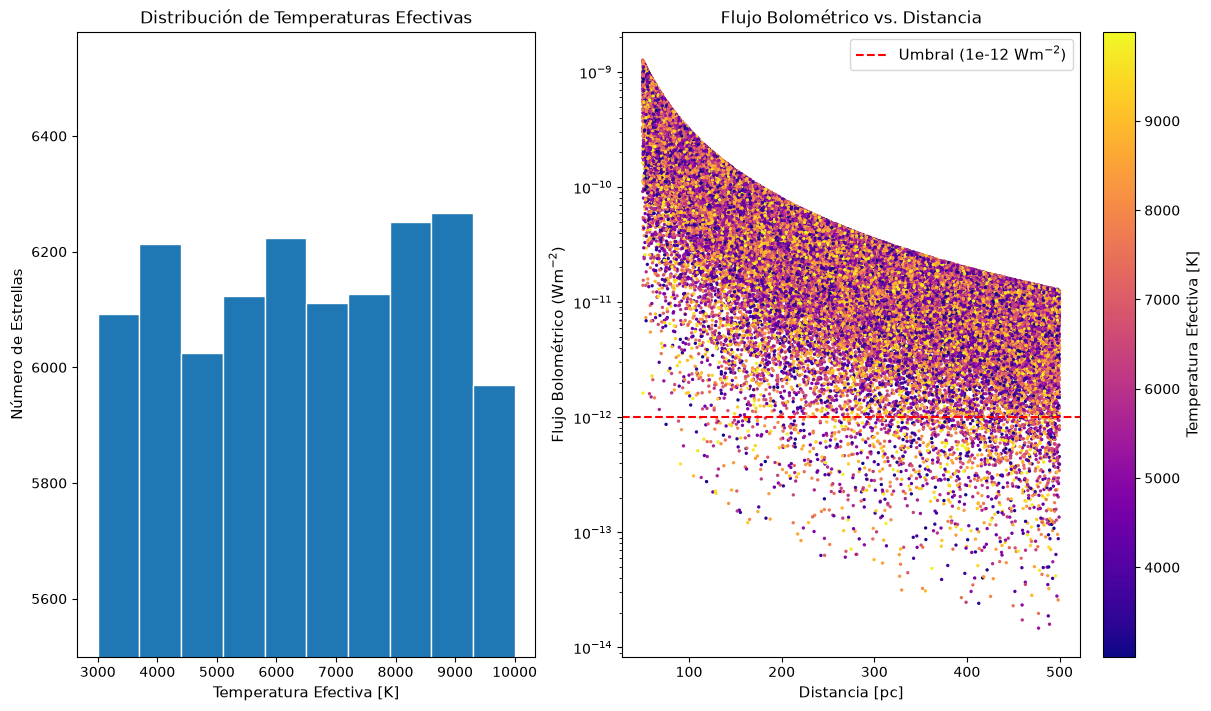

In [26]:
mi_catalogo.graficar_temperatura_flujo(1e-12)

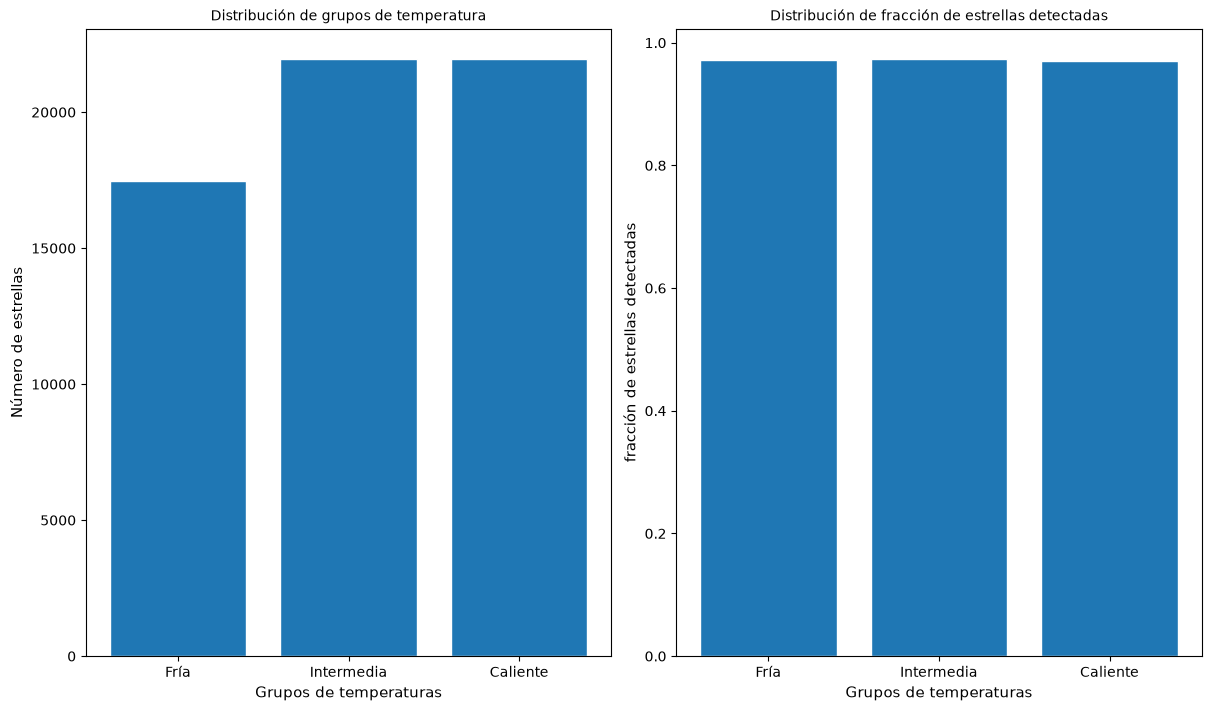

In [27]:
mi_catalogo.graficar_grupos(1e-12)

In [17]:
mi_catalogo.guardar_resultados("PomPompurin", formato="csv") # probé con nombres y los dos tipos de guardado
mi_catalogo.guardar_resultados("PomPompurin", formato="npz")

Guardando archivo...
Archivo CSV exportado exitosamente en: 'PomPompurin.csv'
Guardando archivo...
Archivo NPZ comprimido exportado exitosamente en: 'PomPompurin.npz'


=== DATOS MANUALES ORIGINALES ===
               nombre     L_Lsol      d_pc    T_K
0   Estrella_Prueba_1  5.000e-01 1.000e+01   4000
1   Estrella_Prueba_2  1.000e+00 4.300e+00   5778
2   Estrella_Prueba_3  1.500e+01 1.500e+02   9500
3   Estrella_Prueba_4  1.500e+03 8.000e+02  25000
4   Estrella_Prueba_5  2.000e-02 2.500e+00   3100
5   Estrella_Prueba_6  1.000e+02 4.500e+01  11000
6   Estrella_Prueba_7  5.000e+00 1.250e+01   6000
7   Estrella_Prueba_8 -1.000e+00 3.000e+01   4500
8   Estrella_Prueba_9        NaN 5.000e+01   5200
9  Estrella_Prueba_10  1.200e+01 8.000e+00   7200
Número de datos inicial: 10
Cantidad de números negativos: 1
Cantidad de nan: 1
Número de datos útiles: 8
               nombre  flujo bolométrico [Wm⁻²]  radio estelar [R☉]  \
0   Estrella_Prueba_1                 1.599e-10           1.475e+00   
1   Estrella_Prueba_2                 1.730e-09           1.000e+00   
2   Estrella_Prueba_3                 2.132e-11           1.433e+00   
3   Estrella_Prueba_4     

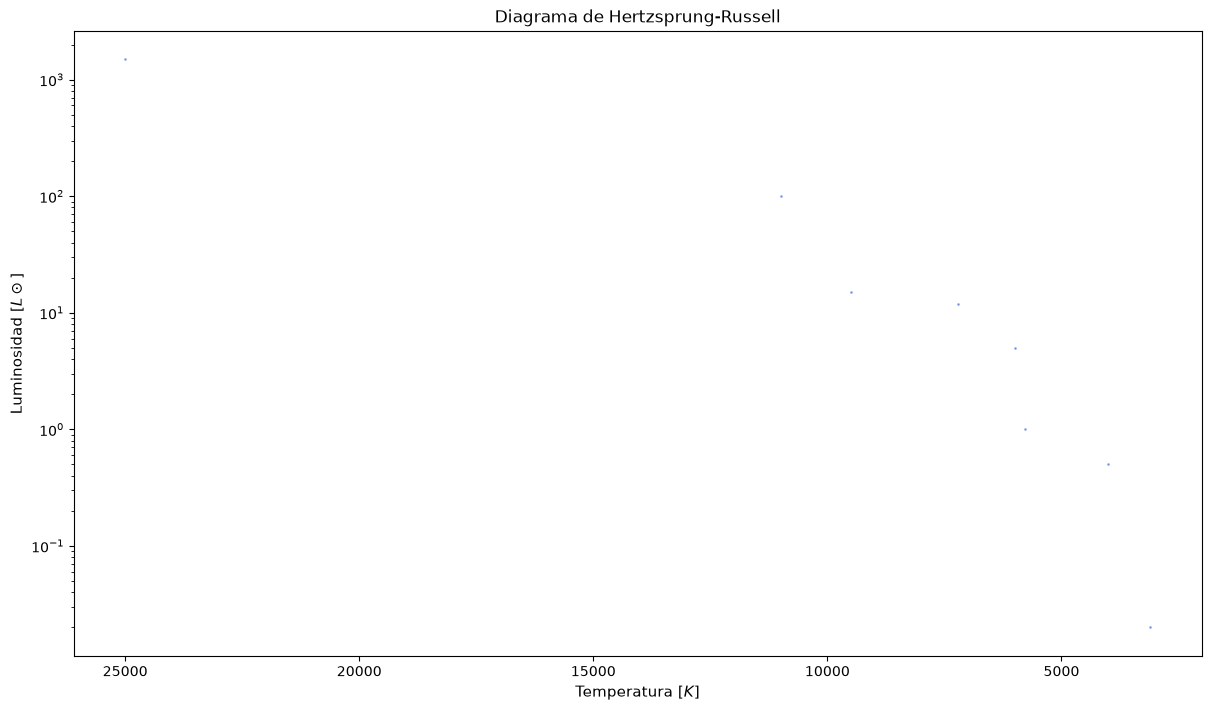

In [18]:
datos_prueba = pd.DataFrame({
    'nombre': [f'Estrella_Prueba_{i}' for i in range(1, 11)],
    'L_Lsol': [0.5, 1.0, 15.0, 1500.0, 0.02, 100.0, 5.0, -1.0, np.nan, 12.0], # Incluye nan y negativo para probar la limpieza
    'd_pc':   [10.0, 4.3, 150.0, 800.0, 2.5, 45.0, 12.5, 30.0, 50.0, 8.0],
    'T_K':    [4000, 5778, 9500, 25000, 3100, 11000, 6000, 4500, 5200, 7200]})
print("=== DATOS MANUALES ORIGINALES ===")
print(datos_prueba.head(10))
catalogo_manual = CatalogoEstelar.desde_dataframe(datos_prueba)
catalogo_manual.calcular_flujo()
catalogo_manual.calcular_radio()
catalogo_manual.calcular_lambda_max()
print(catalogo_manual.datos[['nombre', 'flujo bolométrico [Wm⁻²]', 'radio estelar [R☉]', 'lambda de máxima emisión [nm]']])
# viendo si funciona el grafico...
catalogo_manual.graficar_hr()
